# EXAM TEMPLATE — edit only the lines marked CHANGE ME (runs on wine as the example)
Exam layout (from both instruction sheets):

| Part | Task | Points |
|---|---|---|
| 1 Regression **from scratch** | 1.1 train 4 models (Linear, Multiple, Polynomial, Best) + predict | 8 |
| | 1.2 compare R² and rank the models + predict the given value | 2 |
| 2 Classification **with library** | 2.1 train 4+ classifiers | 8 |
| | 2.2 compare accuracy and F1, rank them | 2 |
| | 2.3 use the regression predictions to predict the class | 3 |

Dataset: **whatever CSV the teacher gives (example: wine)**. Regression target: `quality  (set TARGET below)`. Set CLASS_COL if the CSV has a class column, otherwise THRESHOLD makes classes from the target.

## 0. Load and prepare the data

In [1]:
import os, warnings
os.environ["LOKY_MAX_CPU_COUNT"] = "4"   # silences a harmless joblib warning on Windows
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
np.set_printoptions(suppress=True, precision=4)

In [2]:
df = pd.read_csv('data/winequality-red.csv', sep=';')
print(df.shape)
df.head()

(1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
print(df.isnull().sum().sum(), "missing values")
print(df.dtypes.value_counts())
df.describe().T.head(15)

0 missing values
float64    11
int64       1
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


In [4]:
TARGET = "quality"          # CHANGE ME: regression target column
CLASS_COL = None            # CHANGE ME: class column name if one exists (e.g. "Load_Type"), else None
THRESHOLD = 6               # CHANGE ME: used only when CLASS_COL is None -> class = target >= THRESHOLD
DROP_COLS = []              # CHANGE ME: id / date / leaking columns

df = df.dropna()
X_df = df.drop(columns=[TARGET] + DROP_COLS + ([CLASS_COL] if CLASS_COL else []))
X_df = pd.get_dummies(X_df, drop_first=True).astype(float)
feature_names = list(X_df.columns)
X = X_df.values
y = df[TARGET].values.astype(float)
print(len(feature_names), "features:", feature_names)

11 features: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# numpy-only alternative:
# idx = np.random.default_rng(42).permutation(len(X)); n_te = int(0.2 * len(X))
# X_test, X_train, y_test, y_train = X[idx[:n_te]], X[idx[n_te:]], y[idx[:n_te]], y[idx[n_te:]]
print(X_train.shape, X_test.shape)

(1279, 11) (320, 11)


In [6]:
mu, sd = X_train.mean(0), X_train.std(0)
sd[sd == 0] = 1                       # constant column -> avoid divide by zero
Xtr = (X_train - mu) / sd
Xte = (X_test - mu) / sd

---
# Part 1 — Regression from scratch
## 1.1 The from-scratch toolbox

In [7]:
# ===== from-scratch toolbox (numpy only) =====
def r2_scratch(y, p):
    ss_res = ((y - p) ** 2).sum()          # error left over by the model
    ss_tot = ((y - y.mean()) ** 2).sum()   # error of "always guess the mean"
    return 1 - ss_res / ss_tot

def rmse_scratch(y, p):
    return np.sqrt(((y - p) ** 2).mean())

def add_bias(X):
    return np.c_[np.ones(len(X)), X]      # column of 1s -> intercept theta0

class LinearRegressionScratch:
    """y_hat = X @ theta.  method='ols' (normal equation) or 'gd' (gradient descent).
    lam > 0 adds Ridge (L2) penalty -> stops huge weights / overfitting."""
    def __init__(self, method="ols", lr=0.05, epochs=2000, lam=0.0):
        self.method, self.lr, self.epochs, self.lam = method, lr, epochs, lam
    def fit(self, X, y):
        Xb = add_bias(X)
        n, d = Xb.shape
        if self.method == "ols":
            I = np.eye(d); I[0, 0] = 0          # never penalise the intercept
            self.theta = np.linalg.solve(Xb.T @ Xb + self.lam * I, Xb.T @ y)
        else:
            self.theta = np.zeros(d)
            self.loss_history = []
            for _ in range(self.epochs):
                error = Xb @ self.theta - y               # prediction - truth
                grad = (2 / n) * Xb.T @ error              # d(MSE)/d(theta)
                grad[1:] += 2 * self.lam * self.theta[1:] / n
                self.theta -= self.lr * grad               # step downhill
                self.loss_history.append((error ** 2).mean())
        return self
    def predict(self, X):
        return add_bias(X) @ self.theta

def poly_features(X, degree=2):
    """degree 2: x_i, all x_i*x_j (incl. squares). degree 3: also adds x_i^3."""
    parts = [X]
    n = X.shape[1]
    if degree >= 2:
        parts.append(np.column_stack([X[:, i] * X[:, j] for i in range(n) for j in range(i, n)]))
    if degree >= 3:
        parts.append(X ** 3)
    return np.hstack(parts)

class PolyRegressionScratch:
    def __init__(self, degree=2, lam=1.0):
        self.degree, self.lam = degree, lam
    def fit(self, X, y):
        P = poly_features(X, self.degree)
        self.mu, self.sd = P.mean(0), P.std(0) + 1e-12   # re-scale new columns
        self.lin = LinearRegressionScratch("ols", lam=self.lam).fit((P - self.mu) / self.sd, y)
        return self
    def predict(self, X):
        return self.lin.predict((poly_features(X, self.degree) - self.mu) / self.sd)

class KNNRegressorScratch:
    """Predict = distance-weighted average of the k closest training points."""
    def __init__(self, k=10):
        self.k = k
    def fit(self, X, y):
        self.X, self.y = X, y
        return self
    def predict(self, X):
        out = []
        sq_train = (self.X ** 2).sum(1)
        for i in range(0, len(X), 1000):                       # chunks -> low memory
            A = X[i:i + 1000]
            d2 = (A ** 2).sum(1)[:, None] + sq_train[None, :] - 2 * A @ self.X.T
            d2 = np.maximum(d2, 0)
            nn = np.argpartition(d2, self.k, axis=1)[:, :self.k]
            w = 1 / (np.sqrt(np.take_along_axis(d2, nn, 1)) + 1e-9)
            out.append((self.y[nn] * w).sum(1) / w.sum(1))
        return np.concatenate(out)

class BlendScratch:
    """Best model: weighted average of PolyRidge + KNN.  Two different kinds of model
    make different mistakes, so averaging cancels part of the error (ensemble idea)."""
    def __init__(self, degree=2, lam=10.0, k=15, w=0.5):
        self.poly, self.knn, self.w = PolyRegressionScratch(degree, lam), KNNRegressorScratch(k), w
    def fit(self, X, y):
        self.poly.fit(X, y); self.knn.fit(X, y)
        return self
    def predict(self, X):
        return self.w * self.poly.predict(X) + (1 - self.w) * self.knn.predict(X)

### Model 1 — Simple Linear Regression (1 feature, gradient descent)

best single feature: alcohol | corr = 0.473
GD  theta: [5.6239 0.3813]
OLS theta: [5.6239 0.3813]  <- should match


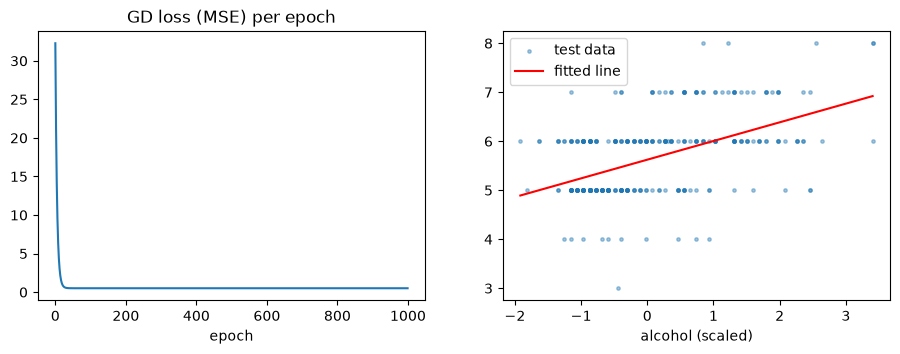

In [8]:
corr = [abs(np.corrcoef(Xtr[:, j], y_train)[0, 1]) for j in range(Xtr.shape[1])]
best_j = int(np.argmax(corr))
print("best single feature:", feature_names[best_j], "| corr = %.3f" % corr[best_j])

m1 = LinearRegressionScratch("gd", lr=0.05, epochs=1000).fit(Xtr[:, [best_j]], y_train)
m1_check = LinearRegressionScratch("ols").fit(Xtr[:, [best_j]], y_train)
print("GD  theta:", m1.theta)
print("OLS theta:", m1_check.theta, " <- should match")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(m1.loss_history); ax[0].set_title("GD loss (MSE) per epoch"); ax[0].set_xlabel("epoch")
ax[1].scatter(Xte[:, best_j], y_test, s=6, alpha=.4, label="test data")
xs = np.linspace(Xte[:, best_j].min(), Xte[:, best_j].max(), 50)
ax[1].plot(xs, m1.predict(xs[:, None]), "r", label="fitted line"); ax[1].legend()
ax[1].set_xlabel(feature_names[best_j] + " (scaled)"); plt.show()

### Model 2 — Multiple Linear Regression (all features)

In [9]:
m2 = LinearRegressionScratch("ols").fit(Xtr, y_train)
print("intercept:", round(m2.theta[0], 4))
print(pd.Series(m2.theta[1:], index=feature_names).sort_values(key=abs, ascending=False).head(8))

intercept: 5.6239
alcohol                 0.296628
volatile acidity       -0.179439
sulphates               0.146815
total sulfur dioxide   -0.120008
chlorides              -0.089084
pH                     -0.060610
free sulfur dioxide     0.058015
fixed acidity           0.039789
dtype: float64


### Model 3 — Polynomial Regression (degree 2)

In [10]:
m3 = PolyRegressionScratch(degree=2, lam=1.0).fit(Xtr, y_train)
print("number of polynomial features:", poly_features(Xtr[:2], 2).shape[1])

number of polynomial features:

 77


### Model 4 — Best model: PolyRidge + KNN blend (tuned)

In [11]:
# tune the Blend on a VALIDATION split carved out of TRAIN (the test set stays untouched)
Xa, Xv, ya, yv = train_test_split(Xtr, y_train, test_size=0.2, random_state=0)
best = (-np.inf, None)
for lam in [1, 10, 100]:
    p_poly = PolyRegressionScratch(2, lam).fit(Xa, ya).predict(Xv)
    for k in [5, 10, 15, 25]:
        p_knn = KNNRegressorScratch(k).fit(Xa, ya).predict(Xv)
        for w in [0, 0.3, 0.5, 0.7, 1]:
            score = r2_scratch(yv, w * p_poly + (1 - w) * p_knn)
            if score > best[0]:
                best = (score, dict(lam=lam, k=k, w=w))
print("best validation R2 = %.4f with %s" % best)
m4 = BlendScratch(degree=2, **best[1]).fit(Xtr, y_train)   # refit on ALL training data

best validation R2 = 0.3977 with {'lam': 1, 'k': 25, 'w': 0.3}


## 1.2 Predict and compare R² (ranking)

,rank,model,R2,RMSE
3,1,4 Best: Blend Poly+KNN,0.519694,0.560252
2,2,3 Polynomial deg2,0.417543,0.616959
1,3,2 Multiple Linear (OLS),0.403180,0.624520
0,4,"1 Linear (1 feature, GD)",0.235618,0.706773


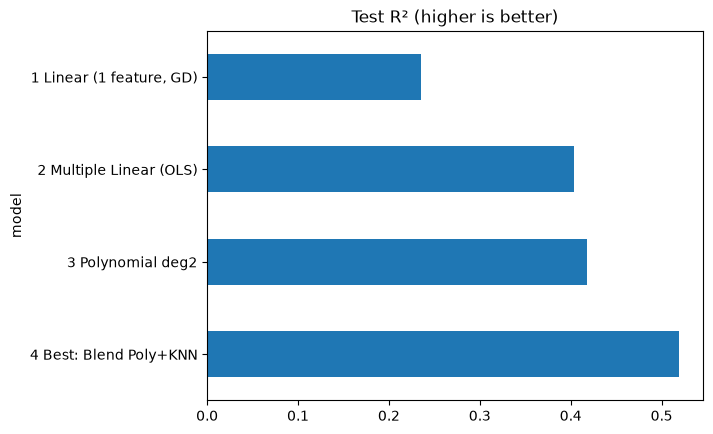

In [12]:
preds_reg = {
    "1 Linear (1 feature, GD)": m1.predict(Xte[:, [best_j]]),
    "2 Multiple Linear (OLS)": m2.predict(Xte),
    "3 Polynomial deg2": m3.predict(Xte),
    "4 Best: Blend Poly+KNN": m4.predict(Xte),
}
rows = [(name, r2_scratch(y_test, p), rmse_scratch(y_test, p)) for name, p in preds_reg.items()]
table_reg = pd.DataFrame(rows, columns=["model", "R2", "RMSE"]).sort_values("R2", ascending=False)
table_reg.insert(0, "rank", range(1, len(table_reg) + 1))
display(table_reg)
table_reg.plot.barh(x="model", y="R2", legend=False, title="Test R² (higher is better)"); plt.show()

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
print("sklearn R2 :", r2_score(y_test, LinearRegression().fit(Xtr, y_train).predict(Xte)))
print("scratch R2 :", r2_scratch(y_test, preds_reg["2 Multiple Linear (OLS)"]))

sklearn R2 : 0.403180341279622
scratch R2 : 0.40318034127962177


### Predict the value the teacher gives (ค่าที่ให้)

In [14]:
def make_row(values: dict):
    raw = pd.DataFrame([values])
    raw = pd.get_dummies(raw).reindex(columns=feature_names, fill_value=0).astype(float)
    for c in feature_names:                      # columns not given -> training mean
        if c not in values and not any(c.startswith(k + "_") for k in values):
            raw[c] = X_train[:, feature_names.index(c)].mean()
    return (raw.values - mu) / sd

given = {"alcohol": 9.4, "volatile acidity": 0.70, "sulphates": 0.56}   # CHANGE ME: the teacher's values
x_new = make_row(given)
for name, m in [("1 Linear", m1), ("2 Multiple", m2), ("3 Polynomial", m3), ("4 Best", m4)]:
    xin = x_new[:, [best_j]] if name.startswith("1") else x_new
    print(f"{name:14s} -> predicted quality  (set TARGET below) = {m.predict(xin)[0]:.3f}")

1 Linear       -> predicted quality  (set TARGET below) = 5.255
2 Multiple     -> predicted quality  (set TARGET below) = 5.083
3 Polynomial   -> predicted quality  (set TARGET below) = 5.037
4 Best         -> predicted quality  (set TARGET below) = 5.124


---
# Part 2 — Classification with library (sklearn)
## 2.1 Build the class label and train classifiers

In [15]:
if CLASS_COL:
    y_cls = np.array(df[CLASS_COL].tolist())
else:
    y_cls = (df[TARGET].values >= THRESHOLD).astype(int)
print(pd.Series(y_cls).value_counts())

1    855
0    744
Name: count, dtype: int64


In [16]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X, y_cls, test_size=0.2, random_state=42)
print(pd.Series(yc_train).value_counts(normalize=True).round(3))

1    0.529
0    0.471
Name: proportion, dtype: float64


In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

In [18]:
classifiers = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN (k=15)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15, weights="distance")),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(C=3, gamma="scale")),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
}
for name, model in classifiers.items():
    model.fit(Xc_train, yc_train)
    print("trained", name)

trained Logistic Regression
trained KNN (k=15)


trained SVM (RBF)
trained Decision Tree


trained Random Forest


### Best classifier — tuned with cross-validation

In [19]:
grid = GridSearchCV(
    HistGradientBoostingClassifier(random_state=42),
    {"learning_rate": [0.05, 0.1], "max_depth": [None, 6], "max_iter": [200, 400]},
    cv=5, scoring="f1_macro", n_jobs=-1)
grid.fit(Xc_train, yc_train)
print("best params:", grid.best_params_, "| CV F1 = %.4f" % grid.best_score_)
classifiers["Best: tuned Gradient Boosting"] = grid.best_estimator_

best params: {'learning_rate': 0.1, 'max_depth': None, 'max_iter': 200} | CV F1 = 0.8037


## 2.2 Predict and compare accuracy and F1 (ranking)

,rank,model,accuracy,F1
5,1,Best: tuned Gradient Boosting,0.818750,0.841530
4,2,Random Forest,0.787500,0.811111
1,3,KNN (k=15),0.781250,0.808743
2,4,SVM (RBF),0.762500,0.784091
0,5,Logistic Regression,0.740625,0.760807
3,6,Decision Tree,0.725000,0.744186


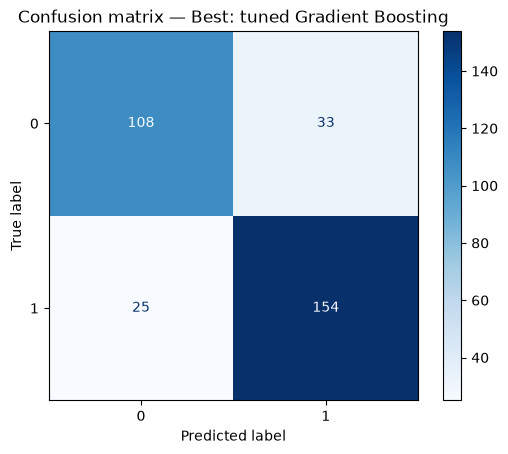

              precision    recall  f1-score   support

           0       0.81      0.77      0.79       141
           1       0.82      0.86      0.84       179

    accuracy                           0.82       320
   macro avg       0.82      0.81      0.81       320
weighted avg       0.82      0.82      0.82       320



In [20]:
avg = "binary" if len(np.unique(y_cls)) == 2 else "macro"
preds_cls = {name: m.predict(Xc_test) for name, m in classifiers.items()}
rows = [(n, accuracy_score(yc_test, p), f1_score(yc_test, p, average=avg)) for n, p in preds_cls.items()]
table_cls = pd.DataFrame(rows, columns=["model", "accuracy", "F1"]).sort_values("F1", ascending=False)
table_cls.insert(0, "rank", range(1, len(table_cls) + 1))
display(table_cls)

best_name = table_cls.iloc[0]["model"]
ConfusionMatrixDisplay.from_predictions(yc_test, preds_cls[best_name], cmap="Blues")
plt.title("Confusion matrix — " + best_name); plt.show()
print(classification_report(yc_test, preds_cls[best_name]))

## 2.3 Use the regression predictions to predict the class

In [21]:
from sklearn.model_selection import KFold
from sklearn.base import clone
rows = []
if not CLASS_COL:   # A. threshold (integer target -> boundary at THRESHOLD - 0.5)
    cut = THRESHOLD - 0.5 if np.all(y == np.round(y)) else THRESHOLD
    for name, p in preds_reg.items():
        c = (p >= cut).astype(int)
        rows.append((name + " -> threshold", accuracy_score(yc_test, c), f1_score(yc_test, c, average=avg)))
# B. stacking: out-of-fold regression prediction as an extra feature
oof = np.zeros(len(Xtr))
for tr_i, va_i in KFold(5, shuffle=True, random_state=42).split(Xtr):
    oof[va_i] = BlendScratch(2, **best[1]).fit(Xtr[tr_i], y_train[tr_i]).predict(Xtr[va_i])
X_stack_tr = np.c_[Xc_train, oof]
X_stack_te = np.c_[Xc_test, preds_reg["4 Best: Blend Poly+KNN"]]
top = table_cls.iloc[0]["model"]
p = clone(classifiers[top]).fit(X_stack_tr, yc_train).predict(X_stack_te)
rows.append((top + " + regression feature", accuracy_score(yc_test, p), f1_score(yc_test, p, average=avg)))
table_23 = pd.concat([table_cls[["model", "accuracy", "F1"]],
                      pd.DataFrame(rows, columns=["model", "accuracy", "F1"])]).sort_values("F1", ascending=False)
table_23.insert(0, "rank", range(1, len(table_23) + 1))
display(table_23.reset_index(drop=True))

,rank,model,accuracy,F1
0,1,Best: tuned Gradient Boosting + regression fea...,0.828125,0.849315
1,2,Best: tuned Gradient Boosting,0.818750,0.841530
2,3,4 Best: Blend Poly+KNN -> threshold,0.812500,0.836066
3,4,Random Forest,0.787500,0.811111
4,5,KNN (k=15),0.781250,0.808743
5,6,SVM (RBF),0.762500,0.784091
6,7,2 Multiple Linear (OLS) -> threshold,0.750000,0.776536
7,8,3 Polynomial deg2 -> threshold,0.743750,0.769663
8,9,Logistic Regression,0.740625,0.760807
9,10,Decision Tree,0.725000,0.744186


### Classify the teacher's given value

In [22]:
x_raw = make_row(given) * sd + mu             # back to unscaled (classifiers take raw X)
for name in table_cls["model"].head(3):
    print(f"{name:32s} -> class {classifiers[name].predict(x_raw)[0]}")

Best: tuned Gradient Boosting    -> class 0
Random Forest                    -> class 0
KNN (k=15)                       -> class 0


---
### Exam checklist
1. Same `random_state=42` everywhere → fair comparison and reproducible numbers.
2. Never fit a scaler or tune anything on TEST.
3. Scratch Model 2 R² == sklearn `LinearRegression` R² → your OLS is correct.
4. Print a **ranked table** for Part 1 (R²) and Part 2 (accuracy and F1). That's the 2-point "compare/rank" item.
5. Write one sentence on *why* the winner wins. Teachers give marks for the reasoning.